In [1]:
import sys
sys.path.append("/hlabhome/wg-mjames/git/Toby_work")
import pandas as pd
import numpy as np
import elephant
from scipy import stats,signal,integrate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression, Lasso
from sklearn import metrics, preprocessing
from sklearn.feature_selection import RFE
import imblearn
from imblearn import over_sampling
from imblearn.under_sampling import RandomUnderSampler
from scipy.stats import ks_2samp
import pickle
import random
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from graphical_functions import *
from helper_functions_math_addons import *
from helper_functions_file_handling import *
from helper_functions_modeling import *
from sklearn.utils.class_weight import compute_sample_weight
from collections import Counter
from threadpoolctl import threadpool_info, threadpool_limits
%load_ext autoreload
%autoreload 2
import os
NCPU = "4"
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
os.environ['VECLIB_MAXIMUM_THREADS'] = '4'
os.environ['NUMEXPR_NUM_THREADS'] = '4'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams.update({'font.family':'DejaVu Sans'})

In [2]:
#Example of getting a dataset downsampled to 5,3,5 chunks from 40%-60%, with defaults left this time
split_thres = (0.4, 0.6)
addon = 'unfiltered'
downlims = [5,3,5]
load_data=True
train_scaled, test_scaled = obtain_train_test_scaled_data(split_thres, addon, load_data, 
                                                          downlims)

Loaded successfully


In [3]:
reversal_to_full = pd.concat([train_scaled, test_scaled])

In [4]:
condensed_dataframe = get_extended_condensed_data(reversal_to_full)

In [14]:
condensed_dataframe

,index,state,region,cell,animal,celltype,geno,cell_no,age,age_group,state_str,cell_state,state_chunks
0,0,2,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,2,caf69_358_1228_0_12_0_wt-2,537
1,367,0,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,0,caf69_358_1228_0_12_0_wt-0,199
2,524,1,ACad,caf69_358_1228_0_12_0_wt,caf69,RSU,wt,0,358,old,1,caf69_358_1228_0_12_0_wt-1,55
3,561,2,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,2,caf69_358_1228_0_12_1_wt-2,94
4,627,0,ACad,caf69_358_1228_0_12_1_wt,caf69,RSU,wt,1,358,old,0,caf69_358_1228_0_12_1_wt-0,59
...,...,...,...,...,...,...,...,...,...,...,...,...,...
12945,1824735,2,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,2,bth100_99_0624_12_24_94_wt-2,1241
12946,1825567,0,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,0,bth100_99_0624_12_24_94_wt-0,216
12947,1825748,1,V1,bth100_99_0624_12_24_94_wt,bth100,RSU,wt,94,99,young,1,bth100_99_0624_12_24_94_wt-1,33
12948,408415,1,ACad,zbr119_112_0604_0_12_75_app_ps1,zbr119,RSU,app_ps1,75,112,young,1,zbr119_112_0604_0_12_75_app_ps1-1,1


In [6]:
groupings, group_labels, _, _, _, _ = get_cell_groupings(condensed_dataframe, by_geno=True, by_age=True)

In [34]:
overall_cms = {}
for ind, group in enumerate(groupings):
    use = condensed_dataframe[condensed_dataframe['cell'].isin(group)]
    animals_in_group = use.animal.unique()
    total_cms = {}
    for throw_out in range(len(animals_in_group)):
        test_cells = use[use['animal']==animals_in_group[throw_out]]['cell']
        train_cells = use[use['animal']!=animals_in_group[throw_out]]['cell']
        #print(test_cells, train_cells)
        train_scaled = reversal_to_full[reversal_to_full['cell'].isin(train_cells)]
        test_scaled = reversal_to_full[reversal_to_full['cell'].isin(test_cells)]
        #print(train_scaled, test_scaled)
        #break
        train_condensed = get_extended_condensed_data(train_scaled)
        models = train_multi_models(train_scaled, sampling_types=['over'], methods=['LogRegGroup'])
        cms = get_cms_multi(test_scaled, models, get_spiking=False, include_timing=False)
        total_cms[f'Holding out Animal #{animals_in_group[throw_out]}'] = cms['LogRegGroup_over']['all in total']
        #print(total_cms)
    #use_cms = {'all in total' : np.mean(list(total_cms['LogRegGroup_over'].values()), axis=0)}
    #print(use_cms)
    overall_cms[group_labels[ind]] = total_cms

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 23.23it/s]


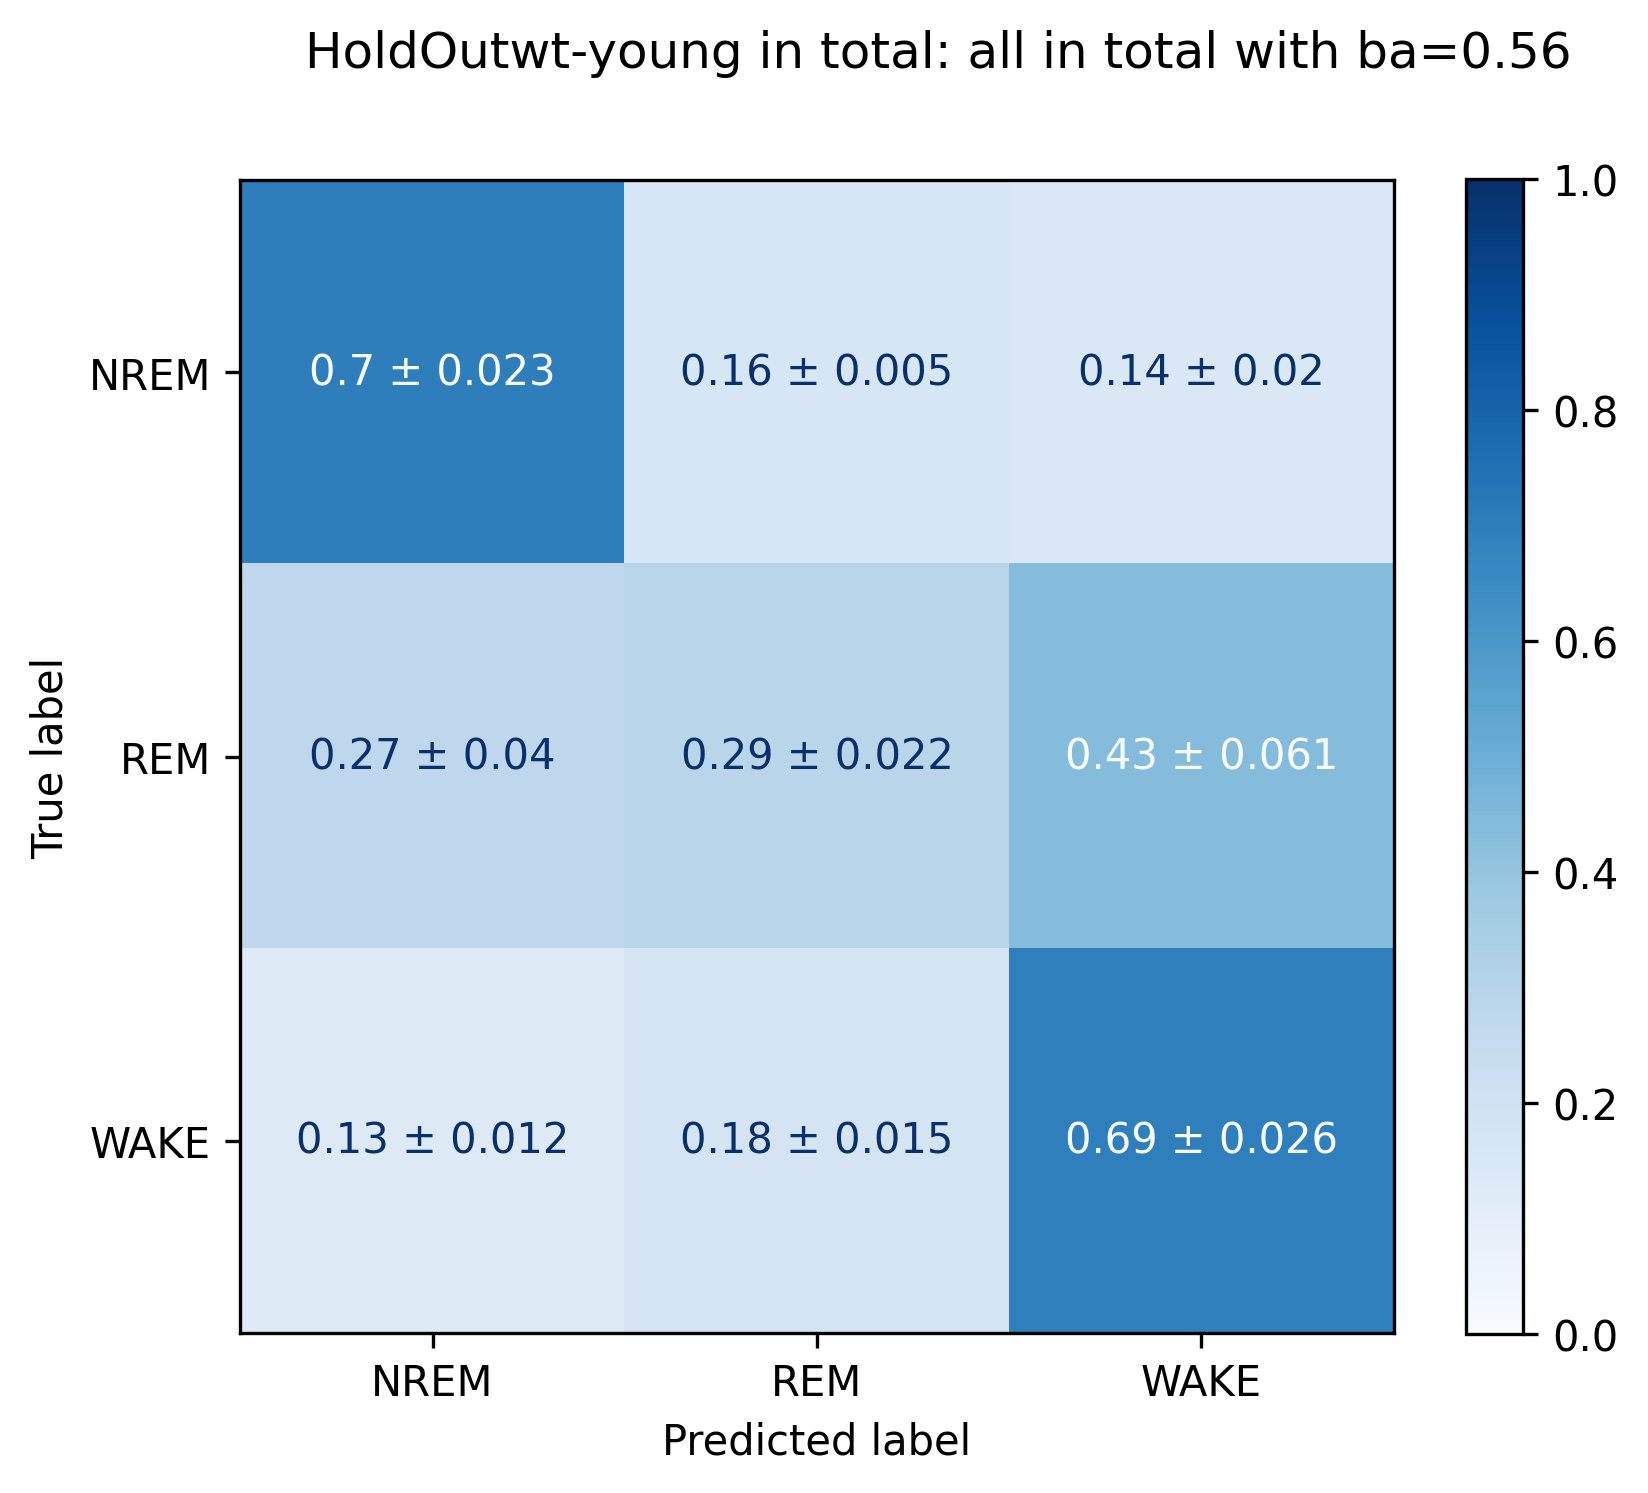

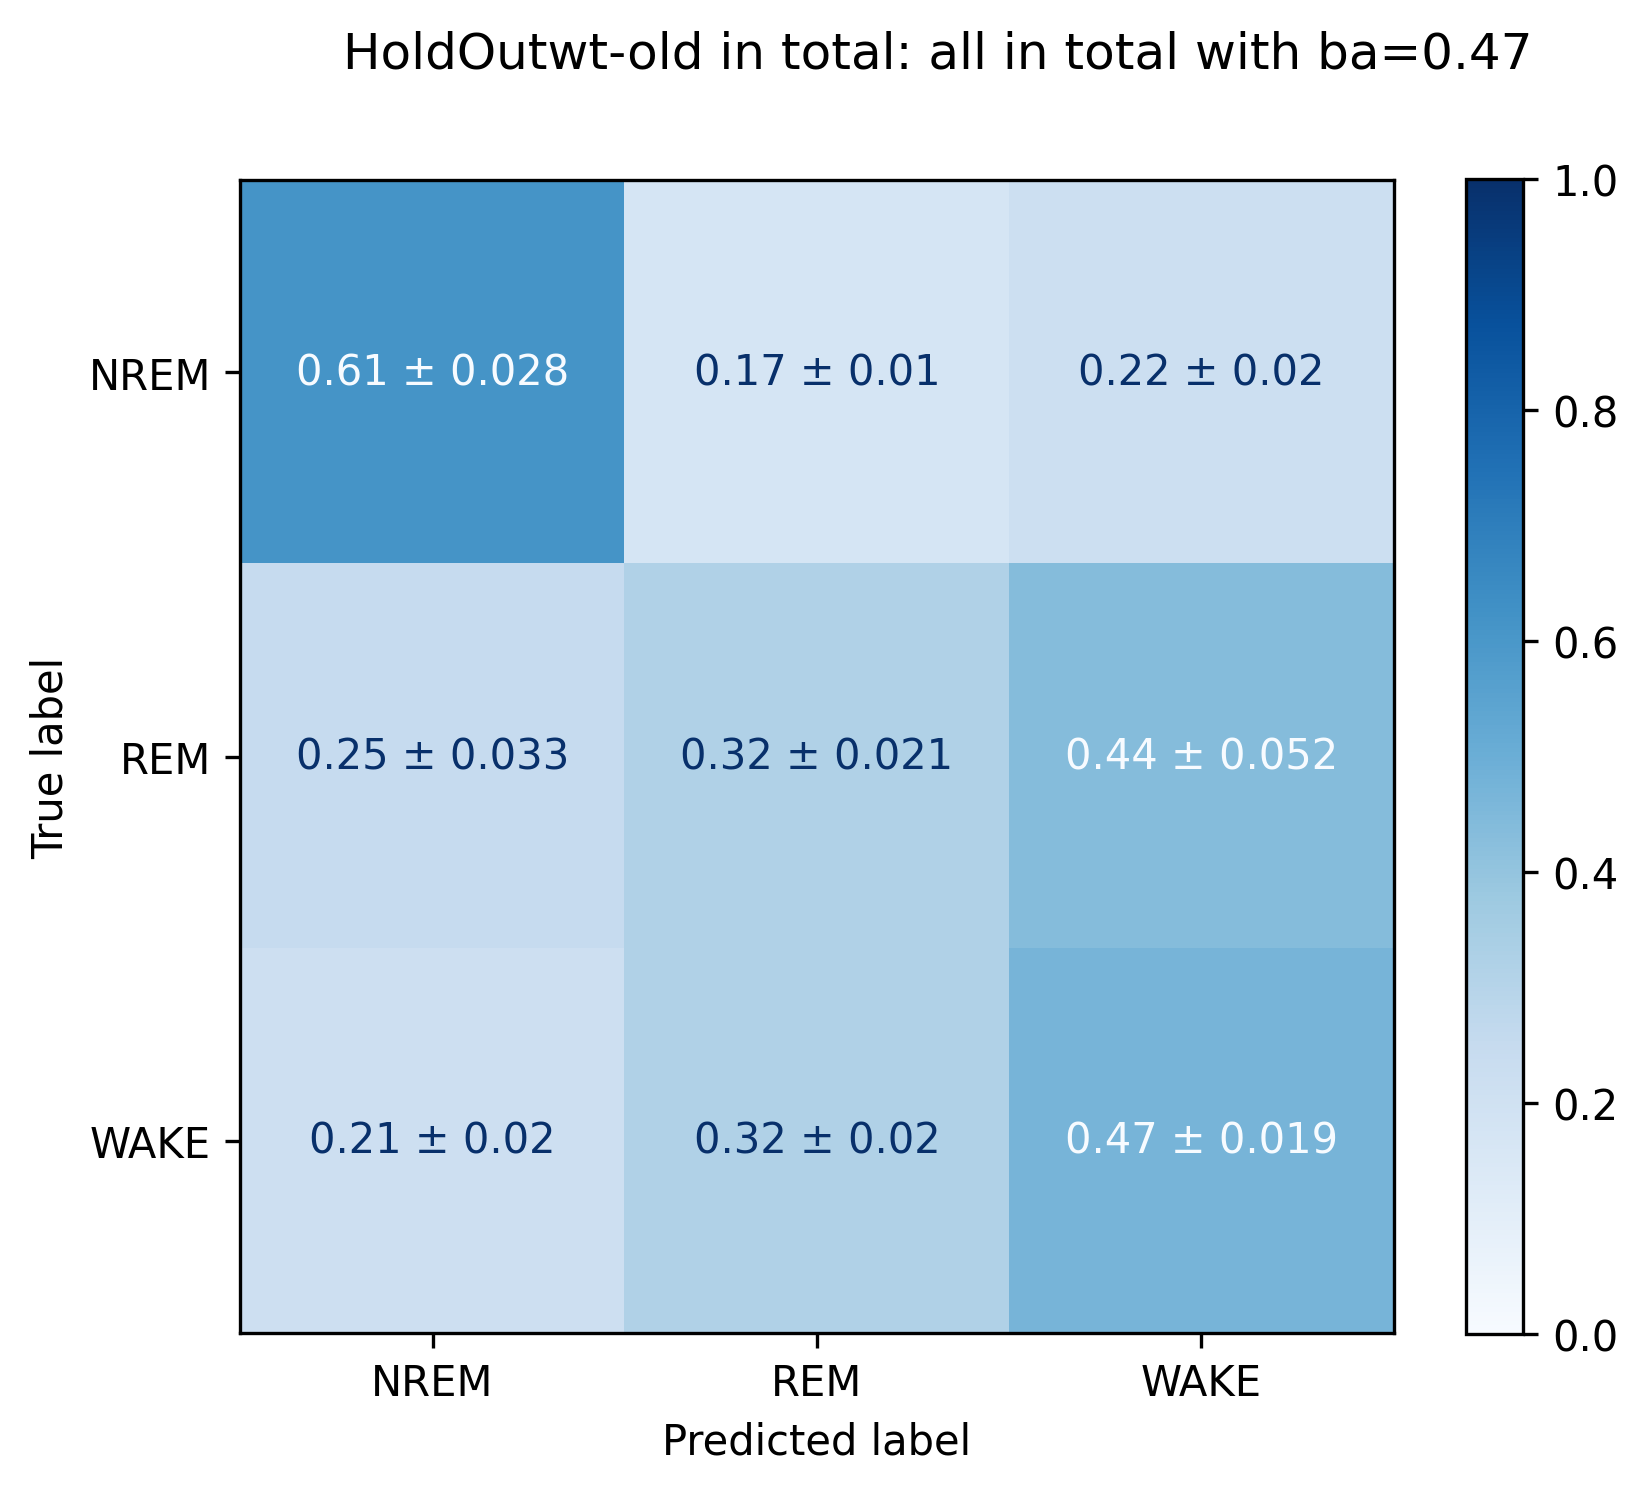

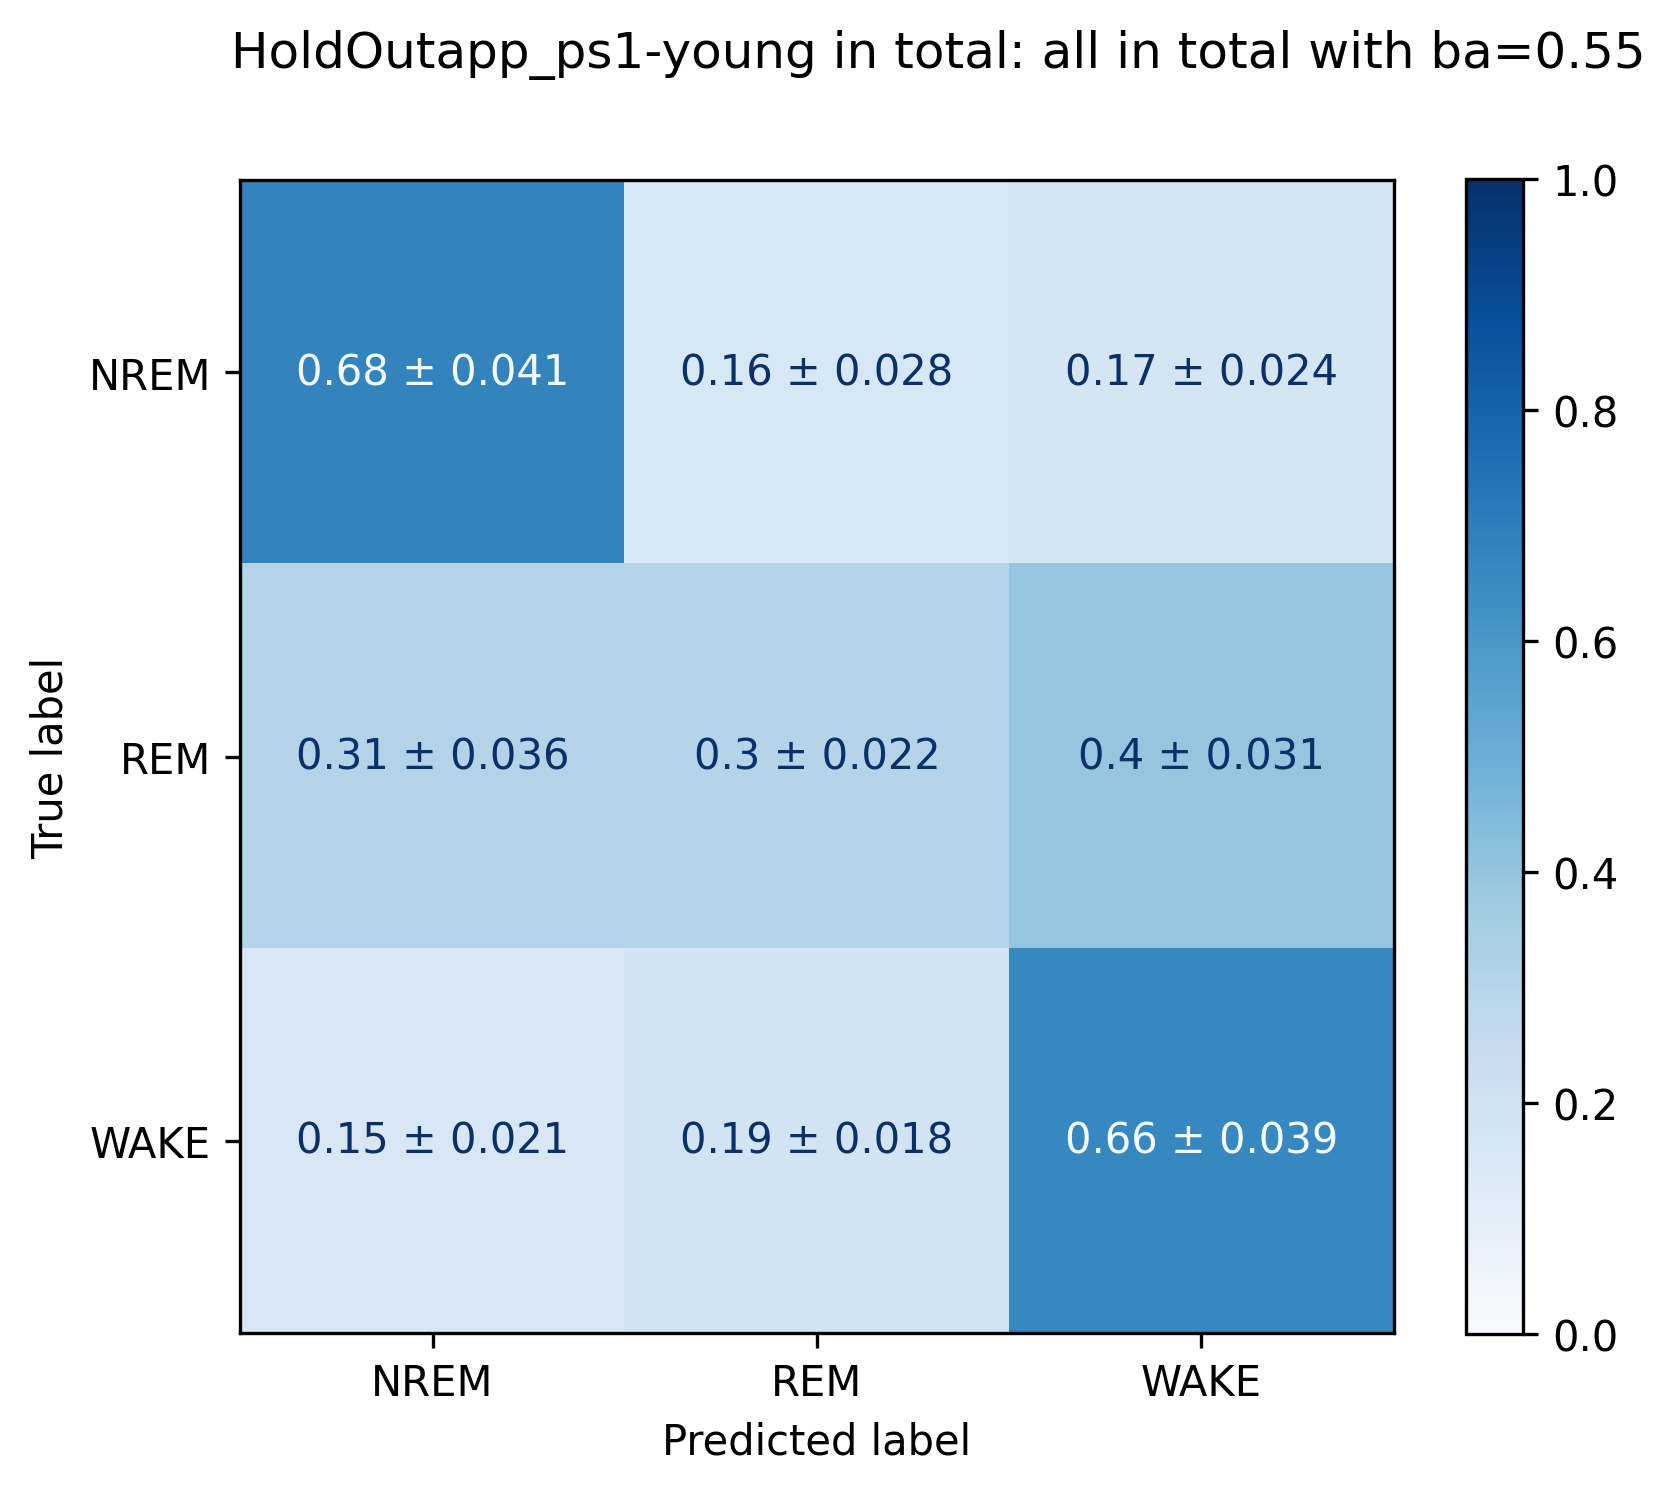

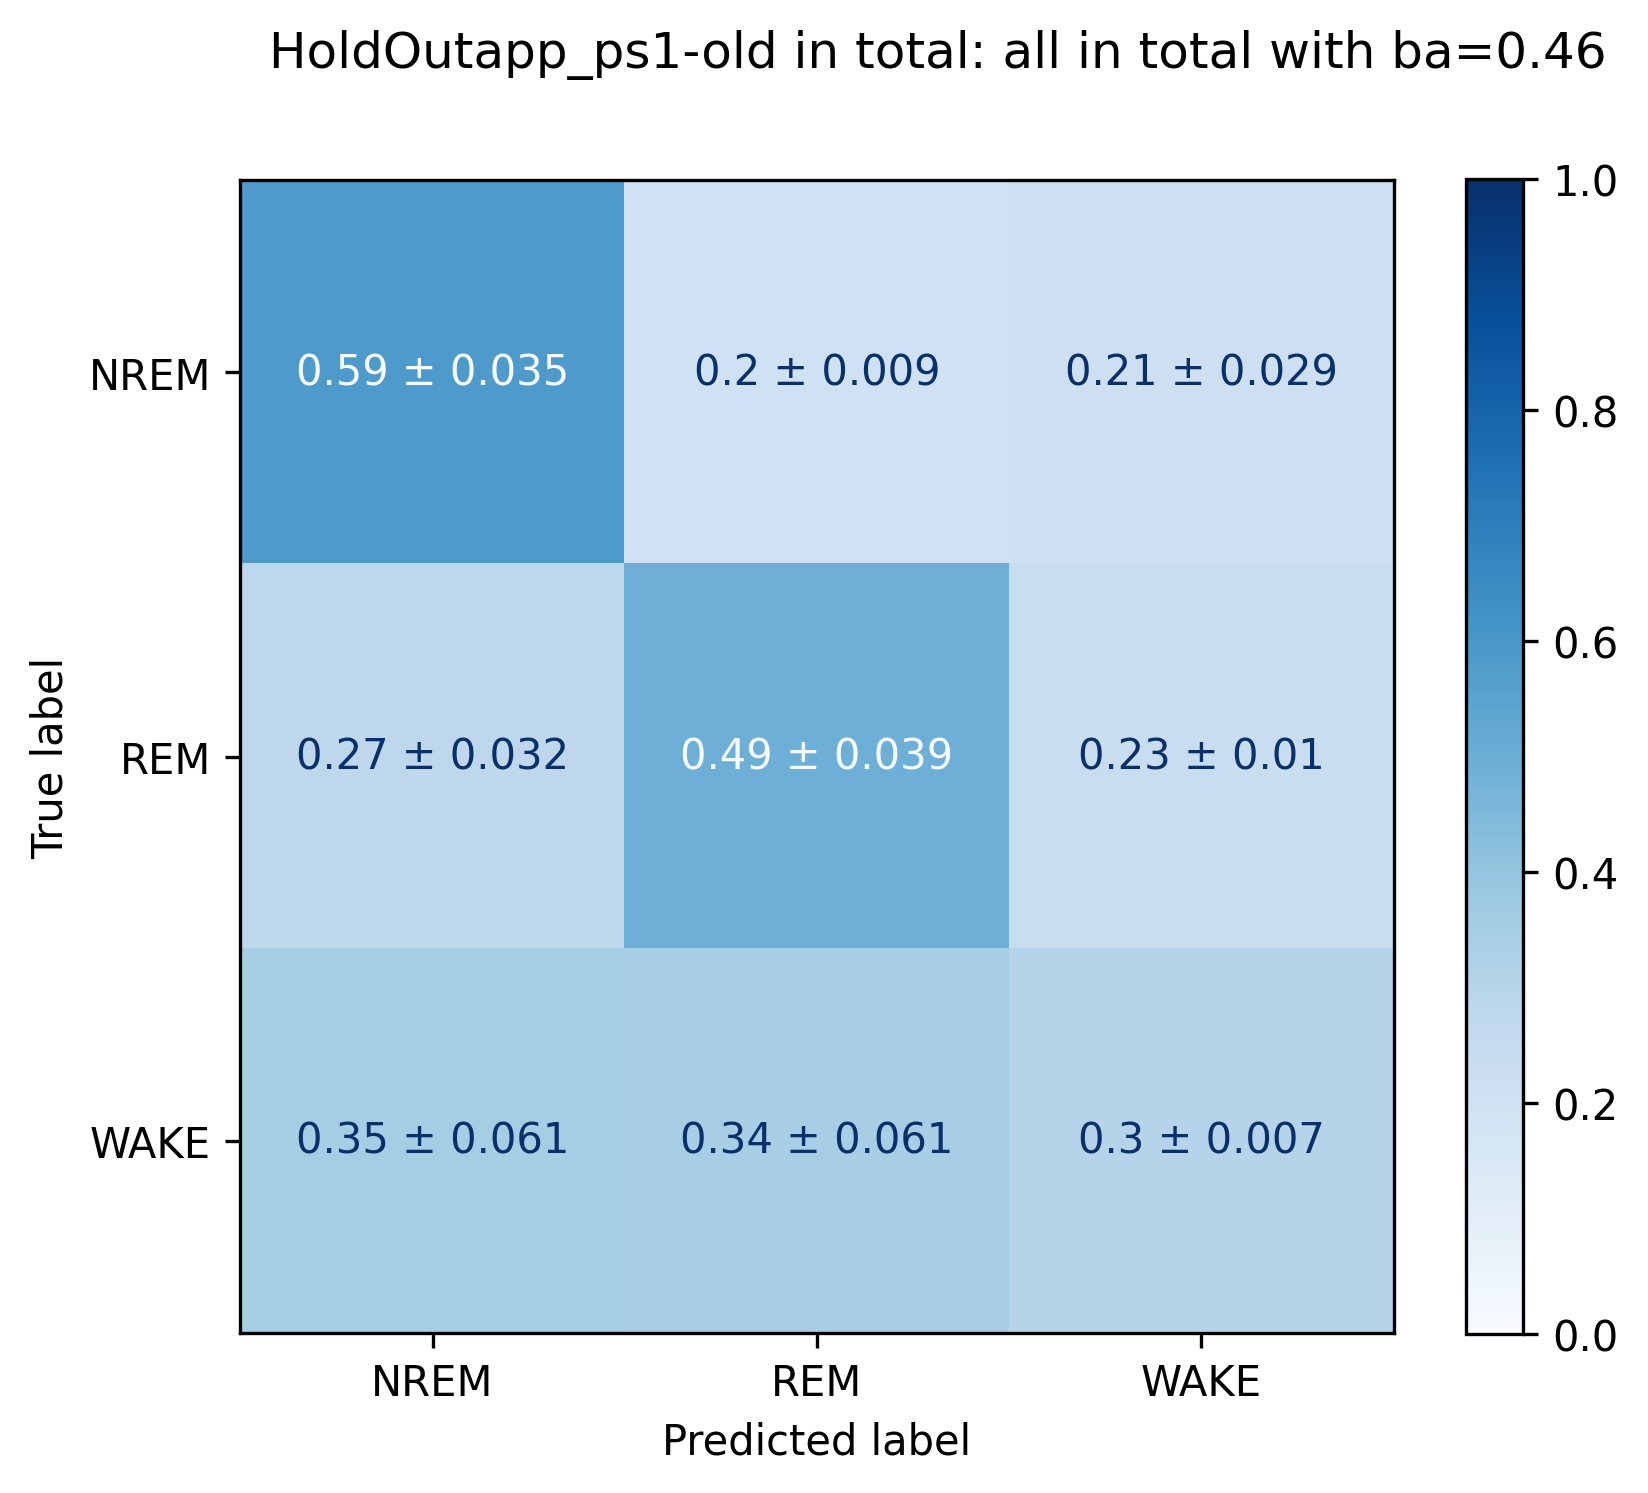

In [38]:
for name, matrices in overall_cms.items():
    get_mean_cms_visual(matrices, train_condensed, f"HoldOut{name}", subplot_kwargs={'figsize':(6.2,5), 'dpi':300}, 
                        addon_text=False, se=True, prev_group_by_anim=True)